<a href="https://colab.research.google.com/github/chana-neuhaus/NYC-traffic-speed-prediction/blob/main/DSC_400_Term_Project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Dependencies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error
import seaborn as sns
import matplotlib.dates as mdates
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
import statsmodels.api as sm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pyspark.ml import Pipeline
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.linalg import Vectors
from pyspark.sql import functions as F
import duckdb

### Introduction

This project utilizes data from NYC DOT speed cameras to analyze speed patterns on two road segments exiting NYC towards New Jersey, and explores whether a predictive model can predict average speeds in a half hour (and resulting levels of congestion), given the time and date and current speeds.

### Obtaining, Loading, and Exploring Data

I used the NYC Open Data API to load three years worht (November 2022 - November 2025) of data, filtering for Lincoln Tunnel and George Washington Bridge, outbound. I load the data into a csv, for easier retrieval later on.

In [2]:
import requests
import pandas as pd

url = 'https://data.cityofnewyork.us/resource/i4gi-tjb9.json'

start = pd.Timestamp('2022-11-16')
end = pd.Timestamp('2025-11-16')  # Exclusive: includes all of November 15

records = []

with requests.Session() as session:
    while start < end:
        batch_end = min(start + pd.Timedelta(days=14), end)

        params = {
            '$select': (
                'link_id,link_name,data_as_of,'
                'speed,travel_time,status'
            ),
            '$where': (
                "link_id IN ('4329507', '4620310') "
                f"AND data_as_of >= '{start:%Y-%m-%d}T00:00:00' "
                f"AND data_as_of < '{batch_end:%Y-%m-%d}T00:00:00'"
            ),
            '$order': 'data_as_of,link_id',
            '$limit': 20000
        }

        response = session.get(url, params=params, timeout=90)
        response.raise_for_status()
        batch = response.json()

        if len(batch) >= 20000:
            raise RuntimeError('Batch hit the row limit; reduce batch size.')

        records.extend(batch)
        print(f'{start.date()} → {batch_end.date()}: {len(batch):,} rows')
        start = batch_end

raw = pd.DataFrame(records)
raw.to_csv('traffic_three_years_raw.csv', index=False)

2022-11-16 → 2022-11-30: 3,148 rows
2022-11-30 → 2022-12-14: 7,745 rows
2022-12-14 → 2022-12-28: 5,212 rows
2022-12-28 → 2023-01-11: 8,061 rows
2023-01-11 → 2023-01-25: 3,522 rows
2023-01-25 → 2023-02-08: 8,060 rows
2023-02-08 → 2023-02-22: 7,980 rows
2023-02-22 → 2023-03-08: 7,794 rows
2023-03-08 → 2023-03-22: 8,029 rows
2023-03-22 → 2023-04-05: 8,064 rows
2023-04-05 → 2023-04-19: 8,056 rows
2023-04-19 → 2023-05-03: 8,044 rows
2023-05-03 → 2023-05-17: 8,047 rows
2023-05-17 → 2023-05-31: 2,016 rows
2023-05-31 → 2023-06-14: 3,180 rows
2023-06-14 → 2023-06-28: 8,029 rows
2023-06-28 → 2023-07-12: 8,047 rows
2023-07-12 → 2023-07-26: 5,250 rows
2023-07-26 → 2023-08-09: 8,064 rows
2023-08-09 → 2023-08-23: 7,956 rows
2023-08-23 → 2023-09-06: 8,056 rows
2023-09-06 → 2023-09-20: 7,976 rows
2023-09-20 → 2023-10-04: 7,696 rows
2023-10-04 → 2023-10-18: 8,040 rows
2023-10-18 → 2023-11-01: 8,013 rows
2023-11-01 → 2023-11-15: 8,035 rows
2023-11-15 → 2023-11-29: 7,982 rows
2023-11-29 → 2023-12-13: 7,7

Data was downloaded from the NYC DOT camera data source. I downloaded three years worth of data (November 2022 - November 2025) from the Lincoln Tunnel and George Washington Bridge road segments exiting the city.

Requirement 1. Data Ingestion and Storage

In [3]:
#Importing
db = duckdb.read_csv("traffic_three_years_raw.csv")
df = duckdb.sql("SELECT * FROM db").df()

Requirement 2. Data Processing and Analysis with Pandas

In [4]:
#inspecting dataset
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 585664 entries, 0 to 585663
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   link_id      585664 non-null  int64         
 1   link_name    585664 non-null  object        
 2   data_as_of   585664 non-null  datetime64[us]
 3   speed        585664 non-null  float64       
 4   travel_time  585664 non-null  int64         
 5   status       585664 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(3), object(1)
memory usage: 26.8+ MB


In [5]:
#displaying descriptive statistics
df.describe()

,link_id,data_as_of,speed,travel_time,status
count,5.856640e+05,585664,585664.000000,585664.000000,585664.000000
mean,4.475040e+06,2024-06-03 15:25:08.666216,29.558976,254.851985,-5.320373
min,4.329507e+06,2022-11-16 00:04:04,0.000000,-36.000000,-101.000000
25%,4.329507e+06,2023-09-13 04:07:48.250000,22.990000,156.000000,0.000000
50%,4.620310e+06,2024-06-11 08:56:33,29.820000,204.000000,0.000000
75%,4.620310e+06,2025-03-02 00:14:18,38.520000,312.000000,0.000000
max,4.620310e+06,2025-11-15 23:58:03,97.550000,8348.000000,0.000000
std,1.454016e+05,NaN,11.140535,228.687486,22.562185


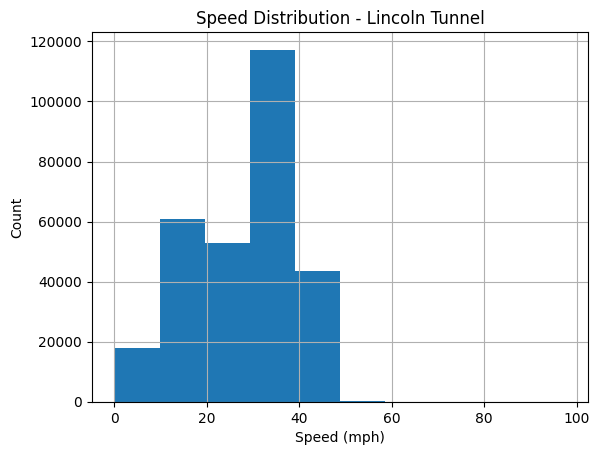

In [6]:
#histogram of speeds on Lincoln Tunnel
lincoln = df[df['link_id']==4329507]
lincoln.hist('speed')
plt.title("Speed Distribution - Lincoln Tunnel")
plt.xlabel("Speed (mph)")
plt.ylabel("Count")
plt.show()

In [7]:
lincoln.describe()

,link_id,data_as_of,speed,travel_time,status
count,292568.0,292568,292568.000000,292568.000000,292568.000000
mean,4329507.0,2024-06-03 07:24:17.965991,27.727876,201.368400,-7.661788
min,4329507.0,2022-11-16 00:04:04,0.000000,-32.000000,-101.000000
25%,4329507.0,2023-09-12 22:31:49,18.010000,134.000000,0.000000
50%,4329507.0,2024-06-10 21:43:33,31.060000,157.000000,0.000000
75%,4329507.0,2025-03-01 07:54:18,36.030000,232.000000,0.000000
max,4329507.0,2025-11-15 23:58:03,97.550000,5051.000000,0.000000
std,0.0,NaN,11.029902,192.851358,26.742102


Text(0, 0.5, 'Count')

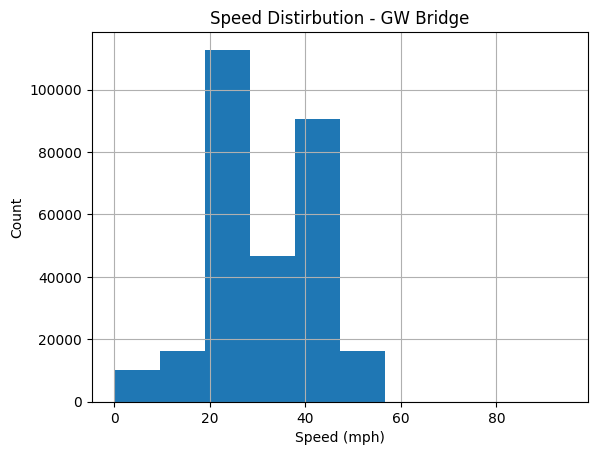

In [8]:
#histogram of speed on GW Bridge
washington = df[df['link_id']==4620310]
washington.hist('speed')
plt.title("Speed Distirbution - GW Bridge")
plt.xlabel("Speed (mph)")
plt.ylabel("Count")

In [9]:
washington.describe()

,link_id,data_as_of,speed,travel_time,status
count,293096.0,293096,293096.000000,293096.000000,293096.000000
mean,4620310.0,2024-06-03 23:25:07.393130,31.386778,308.239222,-2.983176
min,4620310.0,2022-11-16 00:04:04,0.000000,-36.000000,-101.000000
25%,4620310.0,2023-09-13 09:42:49,24.230000,199.000000,0.000000
50%,4620310.0,2024-06-11 20:05:33,29.200000,281.000000,0.000000
75%,4620310.0,2025-03-02 16:34:18,41.630000,337.000000,0.000000
max,4620310.0,2025-11-15 23:58:03,94.440000,8348.000000,0.000000
std,0.0,NaN,10.948631,248.337862,17.099779


In [10]:
#count of values for each road segment
df['link_name'].value_counts()

,count
link_name,
CBE W U/LEV AMSTERDAM AVE - I95 S EXP LNS,293096
LINCOLN TUNNEL W NORTH TUBE NY - NJ,292568


In [11]:
#Average and median speeds for each road segment
df.groupby('link_name')['speed'].agg(mean_speed = 'mean', median_speed = 'median')

,mean_speed,median_speed
link_name,,
CBE W U/LEV AMSTERDAM AVE - I95 S EXP LNS,31.386778,29.20
LINCOLN TUNNEL W NORTH TUBE NY - NJ,27.727876,31.06


In [12]:
#inspecting status
df['status'].value_counts()

,count
status,
0,554813
-101,30851


### Data Wrangling

The histogram clearly showed that there are many instances of zero-mph records. While zero mph is a plausible observation at high levels of congestion, it also could mean an error - perhaps a speed camera malfunction or temporary road closure. As a rule, I removed all zero-mph records recorded on days that were more than 50% zeros. This is not a guarantee that the rest of the zero records are correct, or that all removed records were incorrect, but will hopefully avoid the issue of erroneous outliers influencing the model.

In [14]:
df_clean = df.copy()
df_clean['data_as_of'] = pd.to_datetime(df_clean['data_as_of'])

zero_fraction = df_clean.groupby([
    'link_id',
    df_clean['data_as_of'].dt.normalize()
])['speed'].transform(
    lambda s: s.eq(0).sum() / s.count() if s.count() else np.nan
)

df_clean.loc[zero_fraction > 0.5, 'speed'] = np.nan

###Feature Engineering

I will be using the datetime and speed columns, and creating new variables based on thos features.

List of features:

- *Date (Index)*
- *Month*
- *Day of Week*
- *Hour*
- *minutes*
- *Holiday Indicator*
- *last 5 speeds*
- *Rolling 30 min average*
- *Change in speed over past fifteen minutes*
- *Standard Deviation of speed over past thirty minutes*
- *Road segment*
- *Current Speed*


Target: Speed in next half hour

In [16]:
# setting index to data_as_of
df = df.set_index('data_as_of').sort_index()
df.head(10)

,link_id,link_name,speed,travel_time,status
data_as_of,,,,,
2022-11-16 00:04:04,4329507,LINCOLN TUNNEL W NORTH TUBE NY - NJ,39.14,127,0
2022-11-16 00:04:04,4620310,CBE W U/LEV AMSTERDAM AVE - I95 S EXP LNS,21.74,382,0
2022-11-16 00:09:03,4329507,LINCOLN TUNNEL W NORTH TUBE NY - NJ,36.03,139,0
2022-11-16 00:09:03,4620310,CBE W U/LEV AMSTERDAM AVE - I95 S EXP LNS,27.96,296,0
2022-11-16 00:14:04,4329507,LINCOLN TUNNEL W NORTH TUBE NY - NJ,34.17,145,0
2022-11-16 00:14:04,4620310,CBE W U/LEV AMSTERDAM AVE - I95 S EXP LNS,34.17,244,0
2022-11-16 00:19:03,4329507,LINCOLN TUNNEL W NORTH TUBE NY - NJ,37.28,134,0
2022-11-16 00:19:03,4620310,CBE W U/LEV AMSTERDAM AVE - I95 S EXP LNS,34.79,240,0
2022-11-16 00:24:03,4329507,LINCOLN TUNNEL W NORTH TUBE NY - NJ,36.66,135,0


I resaple the data into clean, five minute intervals. (I use the mean of the records,  but it's mostly one observation per interval.) I group by link_id

In [17]:
#resampling data to five minute intervals
speed = (
    df.groupby('link_id')['speed'].resample('5min', label='right', closed='right').mean()
)
speed.head()

link_id  data_as_of         
4329507  2022-11-16 00:05:00    39.14
         2022-11-16 00:10:00    36.03
         2022-11-16 00:15:00    34.17
         2022-11-16 00:20:00    37.28
         2022-11-16 00:25:00    36.66
Name: speed, dtype: float64

I group by link_id, so my dataframe now has a two-level index (multi-index). I use pandas .shift() to create features for recent speed observations (from five minutes to thirty minutes), as well as the target (speed in thirty minutes), and the standard deviation of speed over the past half hour.

In [18]:
by_segment = speed.groupby(level = 'link_id')
features = speed.to_frame('current_speed')
features['speed_5min_ago']=by_segment.shift(1)
features['speed_10min_ago']=by_segment.shift(2)
features['speed_15min_ago']=by_segment.shift(3)
features['speed_20min_ago']=by_segment.shift(4)
features['speed_25min_ago']=by_segment.shift(5)
features['speed_30min_ago']=by_segment.shift(6)
features['avg_speed_30min']=by_segment.transform(lambda s: s.rolling(6, min_periods=6).mean())
features['std_30min']=by_segment.transform(lambda s: s.rolling(6, min_periods=6).std())
features['target_speed']=by_segment.shift(-6)
features.head(8)


current_speed  speed_5min_ago  speed_10min_ago  \
link_id data_as_of                                                            
4329507 2022-11-16 00:05:00          39.14             NaN              NaN   
        2022-11-16 00:10:00          36.03           39.14              NaN   
        2022-11-16 00:15:00          34.17           36.03            39.14   
        2022-11-16 00:20:00          37.28           34.17            36.03   
        2022-11-16 00:25:00          36.66           37.28            34.17   
        2022-11-16 00:30:00          37.28           36.66            37.28   
        2022-11-16 00:35:00          37.90           37.28            36.66   
        2022-11-16 00:40:00          37.28           37.90            37.28   

                             speed_15min_ago  speed_20min_ago  \
link_id data_as_of                                              
4329507 2022-11-16 00:05:00              NaN              NaN   
        2022-11-16 00:10:00              NaN              NaN   
        2022-11-16 00:15:00              NaN              NaN   
        2022-11-16 00:20:00            39.14              NaN   
        2022-11-16 00:25:00            36.03            39.14   
        2022-11-16 00:30:00            34.17            36.03   
        2022-11-16 00:35:00            37.28            34.17   
        2022-11-16 00:40:00            36.66            37.28   

                             speed_25min_ago  speed_30min_ago  \
link_id data_as_of                                              
4329507 2022-11-16 00:05:00              NaN              NaN   
        2022-11-16 00:10:00              NaN              NaN   
        2022-11-16 00:15:00              NaN              NaN   
        2022-11-16 00:20:00              NaN              NaN   
        2022-11-16 00:25:00              NaN              NaN   
        2022-11-16 00:30:00            39.14              NaN   
        2022-11-16 00:35:00            36.03            39.14   
        2022-11-16 00:40:00            34.17            36.03   

                             avg_speed_30min  std_30min  target_speed  
link_id data_as_of                                                     
4329507 2022-11-16 00:05:00              NaN        NaN         37.90  
        2022-11-16 00:10:00              NaN        NaN         37.28  
        2022-11-16 00:15:00              NaN        NaN         34.79  
        2022-11-16 00:20:00              NaN        NaN         37.90  
        2022-11-16 00:25:00              NaN        NaN         40.38  
        2022-11-16 00:30:00        36.760000   1.640500           NaN  
        2022-11-16 00:35:00        36.553333   1.329296         39.76  
        2022-11-16 00:40:00        36.761667   1.328825         41.01

I extract hour, minute, day of week and month from the index.

In [19]:
idx = features.index.get_level_values(1)
#Extracting hour, minute, weekday, month from index
features['hour'] = idx.hour
features['minute'] = idx.minute
features['weekday'] = idx.day_of_week
features['month'] = idx.month
features.head(20)

current_speed  speed_5min_ago  speed_10min_ago  \
link_id data_as_of                                                            
4329507 2022-11-16 00:05:00          39.14             NaN              NaN   
        2022-11-16 00:10:00          36.03           39.14              NaN   
        2022-11-16 00:15:00          34.17           36.03            39.14   
        2022-11-16 00:20:00          37.28           34.17            36.03   
        2022-11-16 00:25:00          36.66           37.28            34.17   
        2022-11-16 00:30:00          37.28           36.66            37.28   
        2022-11-16 00:35:00          37.90           37.28            36.66   
        2022-11-16 00:40:00          37.28           37.90            37.28   
        2022-11-16 00:45:00          34.79           37.28            37.90   
        2022-11-16 00:50:00          37.90           34.79            37.28   
        2022-11-16 00:55:00          40.38           37.90            34.79   
        2022-11-16 01:00:00            NaN           40.38            37.90   
        2022-11-16 01:05:00          39.76             NaN            40.38   
        2022-11-16 01:10:00          41.01           39.76              NaN   
        2022-11-16 01:15:00          39.76           41.01            39.76   
        2022-11-16 01:20:00          40.38           39.76            41.01   
        2022-11-16 01:25:00          40.38           40.38            39.76   
        2022-11-16 01:30:00          37.90           40.38            40.38   
        2022-11-16 01:35:00          39.76           37.90            40.38   
        2022-11-16 01:40:00          42.25           39.76            37.90   

                             speed_15min_ago  speed_20min_ago  \
link_id data_as_of                                              
4329507 2022-11-16 00:05:00              NaN              NaN   
        2022-11-16 00:10:00              NaN              NaN   
        2022-11-16 00:15:00              NaN              NaN   
        2022-11-16 00:20:00            39.14              NaN   
        2022-11-16 00:25:00            36.03            39.14   
        2022-11-16 00:30:00            34.17            36.03   
        2022-11-16 00:35:00            37.28            34.17   
        2022-11-16 00:40:00            36.66            37.28   
        2022-11-16 00:45:00            37.28            36.66   
        2022-11-16 00:50:00            37.90            37.28   
        2022-11-16 00:55:00            37.28            37.90   
        2022-11-16 01:00:00            34.79            37.28   
        2022-11-16 01:05:00            37.90            34.79   
        2022-11-16 01:10:00            40.38            37.90   
        2022-11-16 01:15:00              NaN            40.38   
        2022-11-16 01:20:00            39.76              NaN   
        2022-11-16 01:25:00            41.01            39.76   
        2022-11-16 01:30:00            39.76            41.01   
        2022-11-16 01:35:00            40.38            39.76   
        2022-11-16 01:40:00            40.38            40.38   

                             speed_25min_ago  speed_30min_ago  \
link_id data_as_of                                              
4329507 2022-11-16 00:05:00              NaN              NaN   
        2022-11-16 00:10:00              NaN              NaN   
        2022-11-16 00:15:00              NaN              NaN   
        2022-11-16 00:20:00              NaN              NaN   
        2022-11-16 00:25:00              NaN              NaN   
        2022-11-16 00:30:00            39.14              NaN   
        2022-11-16 00:35:00            36.03            39.14   
        2022-11-16 00:40:00            34.17            36.03   
        2022-11-16 00:45:00            37.28            34.17   
        2022-11-16 00:50:00            36.66            37.28   
        2022-11-16 00:55:00            37.28            36.66   
        2022-1

I create a 15min_change variable that records the change in speed from 15 minutes ago.

In [20]:

features['15min_change'] = features['current_speed'] - features['speed_15min_ago']
features.head()

current_speed  speed_5min_ago  speed_10min_ago  \
link_id data_as_of                                                            
4329507 2022-11-16 00:05:00          39.14             NaN              NaN   
        2022-11-16 00:10:00          36.03           39.14              NaN   
        2022-11-16 00:15:00          34.17           36.03            39.14   
        2022-11-16 00:20:00          37.28           34.17            36.03   
        2022-11-16 00:25:00          36.66           37.28            34.17   

                             speed_15min_ago  speed_20min_ago  \
link_id data_as_of                                              
4329507 2022-11-16 00:05:00              NaN              NaN   
        2022-11-16 00:10:00              NaN              NaN   
        2022-11-16 00:15:00              NaN              NaN   
        2022-11-16 00:20:00            39.14              NaN   
        2022-11-16 00:25:00            36.03            39.14   

                             speed_25min_ago  speed_30min_ago  \
link_id data_as_of                                              
4329507 2022-11-16 00:05:00              NaN              NaN   
        2022-11-16 00:10:00              NaN              NaN   
        2022-11-16 00:15:00              NaN              NaN   
        2022-11-16 00:20:00              NaN              NaN   
        2022-11-16 00:25:00              NaN              NaN   

                             avg_speed_30min  std_30min  target_speed  hour  \
link_id data_as_of                                                            
4329507 2022-11-16 00:05:00              NaN        NaN         37.90     0   
        2022-11-16 00:10:00              NaN        NaN         37.28     0   
        2022-11-16 00:15:00              NaN        NaN         34.79     0   
        2022-11-16 00:20:00              NaN        NaN         37.90     0   
        2022-11-16 00:25:00              NaN        NaN         40.38     0   

                             minute  weekday  month  15min_change  
link_id data_as_of                                                 
4329507 2022-11-16 00:05:00       5        2     11           NaN  
        2022-11-16 00:10:00      10        2     11           NaN  
        2022-11-16 00:15:00      15        2     11           NaN  
        2022-11-16 00:20:00      20        2     11         -1.86  
        2022-11-16 00:25:00      25        2     11          0.63

I then use the USFederalHolidayCalendar library to add a Boolean is_holiday variable.

In [21]:
cal = USFederalHolidayCalendar()
holidays = cal.holidays(start = '2022-01-01', end='2025-12-31')
features['is_holiday'] = idx.normalize().isin(holidays)
features.head()

current_speed  speed_5min_ago  speed_10min_ago  \
link_id data_as_of                                                            
4329507 2022-11-16 00:05:00          39.14             NaN              NaN   
        2022-11-16 00:10:00          36.03           39.14              NaN   
        2022-11-16 00:15:00          34.17           36.03            39.14   
        2022-11-16 00:20:00          37.28           34.17            36.03   
        2022-11-16 00:25:00          36.66           37.28            34.17   

                             speed_15min_ago  speed_20min_ago  \
link_id data_as_of                                              
4329507 2022-11-16 00:05:00              NaN              NaN   
        2022-11-16 00:10:00              NaN              NaN   
        2022-11-16 00:15:00              NaN              NaN   
        2022-11-16 00:20:00            39.14              NaN   
        2022-11-16 00:25:00            36.03            39.14   

                             speed_25min_ago  speed_30min_ago  \
link_id data_as_of                                              
4329507 2022-11-16 00:05:00              NaN              NaN   
        2022-11-16 00:10:00              NaN              NaN   
        2022-11-16 00:15:00              NaN              NaN   
        2022-11-16 00:20:00              NaN              NaN   
        2022-11-16 00:25:00              NaN              NaN   

                             avg_speed_30min  std_30min  target_speed  hour  \
link_id data_as_of                                                            
4329507 2022-11-16 00:05:00              NaN        NaN         37.90     0   
        2022-11-16 00:10:00              NaN        NaN         37.28     0   
        2022-11-16 00:15:00              NaN        NaN         34.79     0   
        2022-11-16 00:20:00              NaN        NaN         37.90     0   
        2022-11-16 00:25:00              NaN        NaN         40.38     0   

                             minute  weekday  month  15min_change  is_holiday  
link_id data_as_of                                                             
4329507 2022-11-16 00:05:00       5        2     11           NaN       False  
        2022-11-16 00:10:00      10        2     11           NaN       False  
        2022-11-16 00:15:00      15        2     11           NaN       False  
        2022-11-16 00:20:00      20        2     11         -1.86       False  
        2022-11-16 00:25:00      25        2     11          0.63       False

### EDA

In [22]:
eda = features.reset_index()
eda.head()

,link_id,data_as_of,current_speed,speed_5min_ago,speed_10min_ago,speed_15min_ago,speed_20min_ago,speed_25min_ago,speed_30min_ago,avg_speed_30min,std_30min,target_speed,hour,minute,weekday,month,15min_change,is_holiday
0,4329507,2022-11-16 00:05:00,39.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.90,0,5,2,11,NaN,False
1,4329507,2022-11-16 00:10:00,36.03,39.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.28,0,10,2,11,NaN,False
2,4329507,2022-11-16 00:15:00,34.17,36.03,39.14,NaN,NaN,NaN,NaN,NaN,NaN,34.79,0,15,2,11,NaN,False
3,4329507,2022-11-16 00:20:00,37.28,34.17,36.03,39.14,NaN,NaN,NaN,NaN,NaN,37.90,0,20,2,11,-1.86,False
4,4329507,2022-11-16 00:25:00,36.66,37.28,34.17,36.03,39.14,NaN,NaN,NaN,NaN,40.38,0,25,2,11,0.63,False


Requirement 3. Data Visualization (Interactive visualization later in notebook)

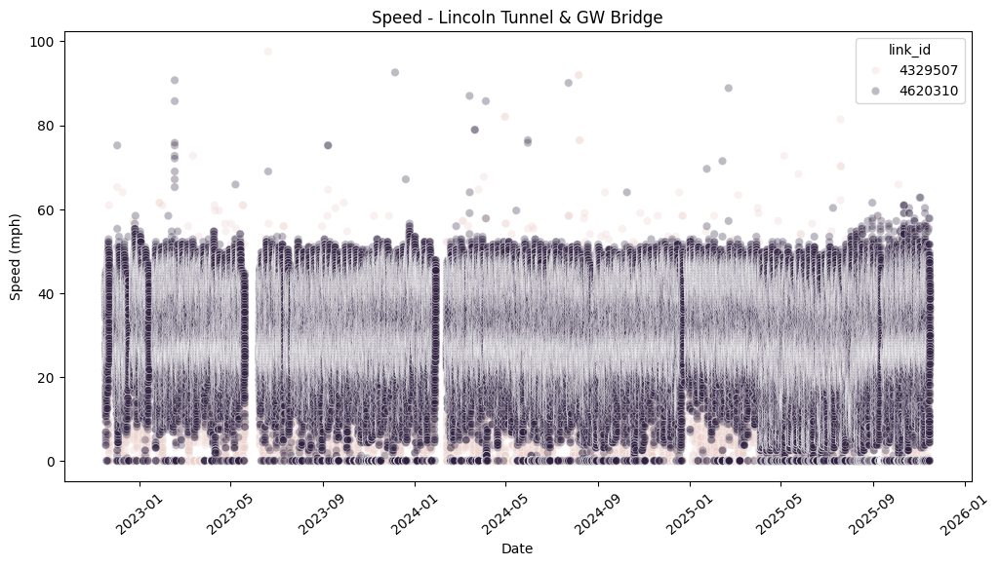

In [23]:
#creating scatterplot of speed
plt.figure(figsize=(12,6))
ax = sns.scatterplot(x=eda['data_as_of'], y=eda['current_speed'], hue=eda['link_id'], alpha=0.3)
plt.xticks(rotation=40)
plt.title("Speed - Lincoln Tunnel & GW Bridge")
plt.xlabel("Date")
plt.ylabel("Speed (mph)")
plt.show()

This scatterplot is hard to interpret, because of the amount of observations.

There seems to be a lot of variation on a typical day, but also potentially some patterns across different times.

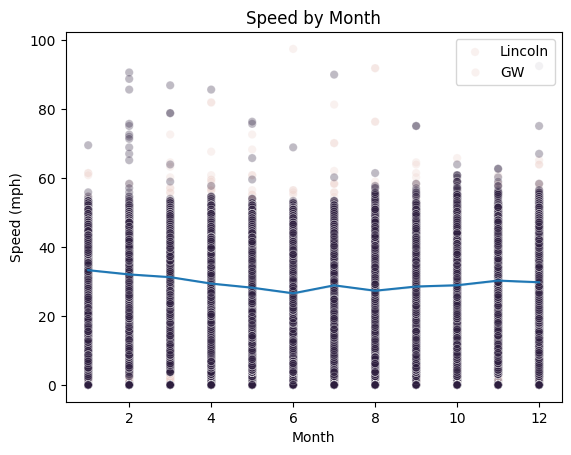

In [24]:
ax = sns.scatterplot(x = eda['data_as_of'].dt.month, y=eda['current_speed'], hue=eda['link_id'], alpha=0.3)
sns.lineplot(x=idx.month, y=features['current_speed'])
plt.title("Speed by Month")
plt.xlabel("Month")
plt.ylabel("Speed (mph)")
plt.legend(labels = ['Lincoln',"GW"], loc='upper right')
plt.show()

Next, I display a scatterplot of speeds by month, and we can see a clearer, if subtle, trend. Interestingly, average speeds are low in some of the summer months.

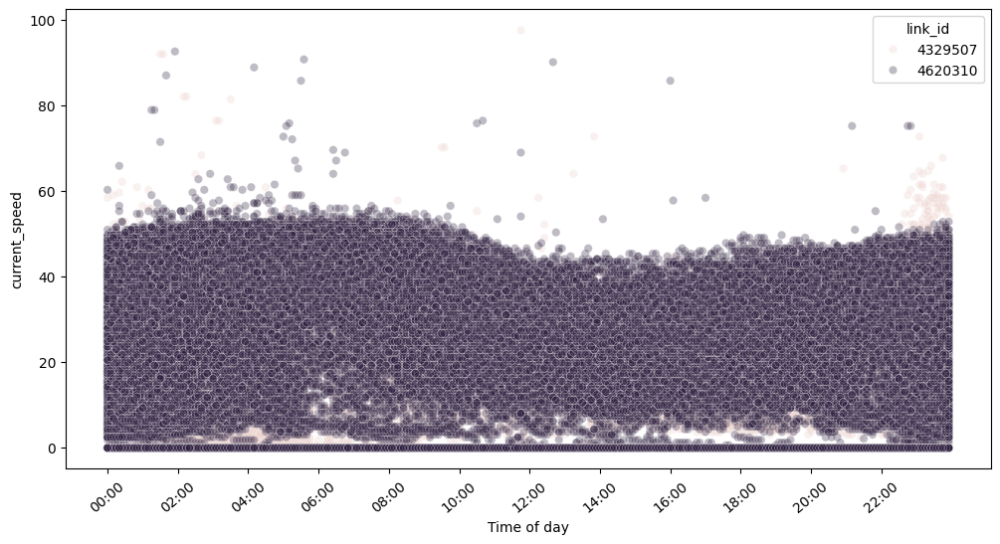

In [25]:
minutes = eda['data_as_of'].dt.hour*60 + eda['data_as_of'].dt.minute
plt.figure(figsize=(12,6))
ax = sns.scatterplot(x=minutes,y=eda['current_speed'], hue=eda['link_id'], alpha=0.3)
ticks = range(0, 1440, 120)
ax.set_xticks(ticks)
ax.set_xticklabels([f'{t // 60:02d}:00' for t in ticks])
ax.set_xlabel('Time of day')
plt.xticks(rotation=40)
plt.show()

Next, I display a scatterplot of speeds against time of day, and there it's easiest to see a clear trend. As we might expect, speeds peak during midnight hours, and are the lowest during the afternoon-evening.

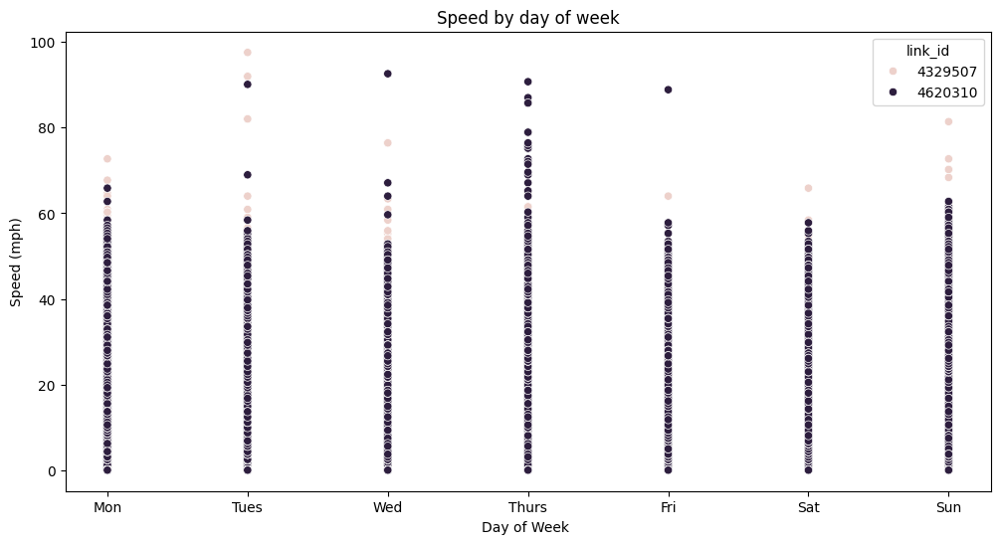

In [26]:
plt.figure(figsize=(12,6))
ax = sns.scatterplot(x=eda['data_as_of'].dt.day_of_week, y=eda['current_speed'], hue = eda['link_id'])
plt.title("Speed by day of week")
plt.xlabel("Day of Week ")
plt.xticks(ticks = [0,1,2,3,4,5,6], labels = ['Mon', 'Tues', 'Wed', 'Thurs', 'Fri', 'Sat', 'Sun'])
plt.ylabel('Speed (mph)')
plt.show()

Next, I display speed by day of week. Speeds are slowest on Friday, and seem to be highest on Thursday.

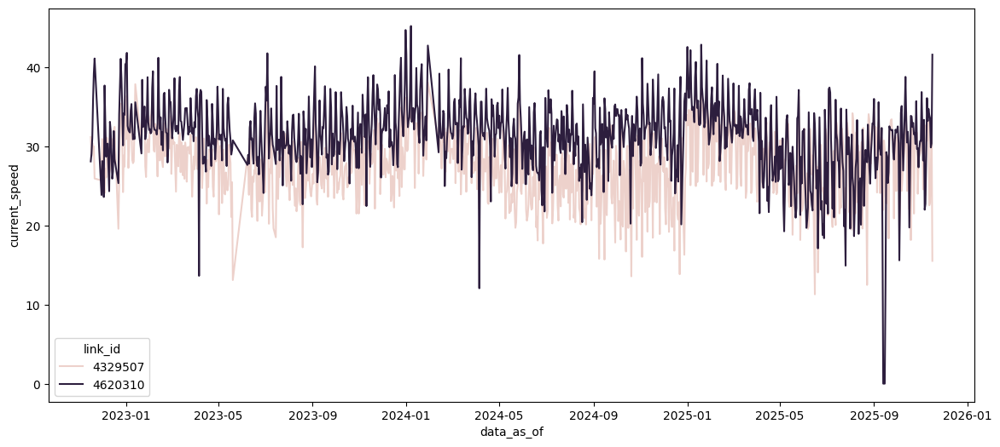

In [28]:
daily = eda.groupby('link_id').resample('D', on='data_as_of')['current_speed'].mean().reset_index()
plt.figure(figsize=(14,6))
sns.lineplot(x=daily['data_as_of'], y=daily['current_speed'], hue=daily['link_id'])
plt.show()

Since scatterplots with all observations are hard to read, I display the rolling average over time. There, it is cleare to observe seasonality in the data. It is also clear that link_id 4620310 experiences higher average speeds than the other road segment.

/tmp/ipykernel_734/1566356067.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])


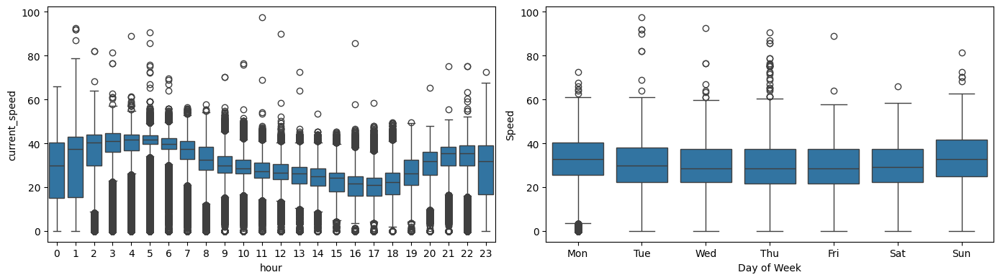

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=eda, x='hour', y='current_speed', ax=axes[0])
plt.xlabel('Hour')
plt.ylabel('Speed')
sns.boxplot(data=eda, x='weekday', y='current_speed', ax=axes[1])
plt.xlabel("Day of Week")
plt.ylabel("Speed")
axes[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])

plt.tight_layout()
plt.show()

Lastly, I display boxplots of data grouped by hour, and grouped by day of week to understand how these variables impact median speeds. We see a clear trend in the hour groups (as noted earlier), with less of a significant pattern by day of week, though Sunday and Monday have noticeably higher median speeds.

In [30]:
eda.corr()

,link_id,data_as_of,current_speed,speed_5min_ago,speed_10min_ago,speed_15min_ago,speed_20min_ago,speed_25min_ago,speed_30min_ago,avg_speed_30min,std_30min,target_speed,hour,minute,weekday,month,15min_change,is_holiday
link_id,1.000000e+00,-1.085666e-14,0.164193,0.164190,0.164186,0.164183,0.164180,0.164178,0.164175,0.173936,-0.083324,0.164200,3.937694e-14,8.900644e-16,-9.100238e-15,1.821509e-14,0.000213,7.249226e-15
data_as_of,-1.085666e-14,1.000000e+00,-0.062393,-0.062393,-0.062394,-0.062394,-0.062394,-0.062395,-0.062397,-0.060324,0.033375,-0.062380,8.933841e-04,2.039951e-05,1.270127e-05,1.150008e-01,0.000020,-6.743693e-03
current_speed,1.641933e-01,-6.239304e-02,1.000000,0.945221,0.898223,0.864007,0.833883,0.806729,0.782683,0.934646,-0.150240,0.782683,-2.221526e-01,-5.921908e-03,2.691889e-03,-8.093294e-02,0.259848,7.427379e-02
speed_5min_ago,1.641900e-01,-6.239299e-02,0.945221,1.000000,0.945221,0.898222,0.864007,0.833883,0.806729,0.958687,-0.151186,0.759960,-2.182343e-01,-4.986685e-03,1.197749e-03,-8.098760e-02,0.089705,7.430768e-02
speed_10min_ago,1.641863e-01,-6.239362e-02,0.898223,0.945221,1.000000,0.945220,0.898222,0.864006,0.833882,0.969857,-0.152890,0.739771,-2.145488e-01,-3.469294e-03,-2.668515e-04,-8.104005e-02,-0.090302,7.434222e-02
speed_15min_ago,1.641829e-01,-6.239390e-02,0.864007,0.898222,0.945220,1.000000,0.945220,0.898222,0.864006,0.969869,-0.155806,0.720968,-2.109331e-01,-7.872914e-04,-1.841433e-03,-8.108857e-02,-0.261675,7.433850e-02
speed_20min_ago,1.641800e-01,-6.239431e-02,0.833883,0.864007,0.898222,0.945220,1.000000,0.945220,0.898222,0.958625,-0.157705,0.702705,-2.078585e-01,2.149300e-03,-3.335617e-03,-8.113921e-02,-0.214309,7.439271e-02
speed_25min_ago,1.641775e-01,-6.239533e-02,0.806729,0.833883,0.864006,0.898222,0.945220,1.000000,0.945220,0.934370,-0.155683,0.685244,-2.052850e-01,8.288500e-04,-4.796037e-03,-8.118675e-02,-0.176222,7.442776e-02
speed_30min_ago,1.641754e-01,-6.239699e-02,0.782683,0.806729,0.833882,0.864006,0.898222,0.945220,1.000000,0.896566,-0.150057,0.668691,-2.031781e-01,4.006096e-03,-6.257734e-03,-8.123186e-02,-0.156808,7.451500e-02
avg_speed_30min,1.739358e-01,-6.032415e-02,0.934646,0.958687,0.969857,0.969869,0.958625,0.934370,0.896566,1.000000,-0.161283,0.769356,-2.392635e-01,-2.587301e-03,7.880491e-04,-8.392542e-02,-0.068565,7.826653e-02


I also displayed a correlation matrix to understand how my independent variables correlate with the target. Noteably, the current_speed variable is still the strongest predictor of target_speed. But other features (mostly the recent speeds) also have significant correlations.

### Train Test Split

I split data chronologically into train and test sets, and also fix up one feature. (The separate features hour and minute become fractional hours, incorporating both into one column.) 80% of the data will be used for training.

In [31]:
data = features.dropna()
X = data.drop(columns = 'target_speed')
X['link_id'] = X.index.get_level_values(0)
X['fractional_hour'] = X['hour'] + X['minute']/60
X = X.drop(columns = ['hour', 'minute'])
y=data['target_speed']
timestamps = data.index.get_level_values(1)
unique_times = timestamps.unique().sort_values()
cutoff = unique_times[int(len(unique_times)*0.8)]
train_mask = timestamps < cutoff - pd.Timedelta(minutes=30)
test_mask = timestamps >= cutoff

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((447079, 15), (111442, 15), (447079,), (111442,))

### Baseline Model

Before I build any predictive models, I build a baseline model, which given current_speed predicts that value will persist in thirty minutes.

In [57]:
#building baseline model function
def baseline_pred(value):
  return(value)
baseline_preds = baseline_pred(X_test['current_speed'])
#Evaluating baseline model performance
print(f"Mean Absolute Error: {mean_absolute_error(y_test, baseline_preds)}")
print(f"Root Mean Squared Error: {root_mean_squared_error(y_test, baseline_preds)} ")

Mean Absolute Error: 4.548908131584143
Root Mean Squared Error: 7.934995691666473 


The baseline model actually performs reasonably well, with a mean absolute error of 4.54  , meaning that on average a prediction will be only about 4.5 points off, and a Root Mean Squared Error of 7.93, meaning that some model errors are much higher, but not too often. It might be hard to beat this with a predictive model.

In [60]:
#evaluating error separately for road segments
lincoln = data[data.index.get_level_values(0) == 4329507]
lincoln_preds = baseline_pred(lincoln['current_speed'])
print(f"Mean Absolute Error: {mean_absolute_error(lincoln['target_speed'], lincoln_preds)}")
print(f"Root Mean Squared Error: {root_mean_squared_error(lincoln['target_speed'], lincoln_preds)} ")

Mean Absolute Error: 4.486514965289224
Root Mean Squared Error: 7.669492068943368 


In [61]:
washington = data[data.index.get_level_values(0) == 4620310]
washington_preds = baseline_pred(washington['current_speed'])
print(f"Mean Absolute Error: {mean_absolute_error(washington['target_speed'], washington_preds)}")
print(f"Root Mean Squared Error: {root_mean_squared_error(washington['target_speed'], washington_preds)} ")

Mean Absolute Error: 3.9939086707339624
Root Mean Squared Error: 6.9591112254783605 


For the Washington Bridge, the MAE and RMSE are even lower.

In [62]:
#Analyzing residuals
baseline_resids = baseline_preds - y_test
baseline_resids.describe()

,0
count,111442.000000
mean,0.002310
std,7.935031
min,-81.390000
25%,-2.480000
50%,0.000000
75%,2.480000
max,81.390000


This reinforces our estimation of the model's performance, with 50% of the model's predictions being within 3 points of the actual. The minimum and maximum residuals are extremely high though, which is likely what yielded the higher MAE and RMSE.

<Axes: >

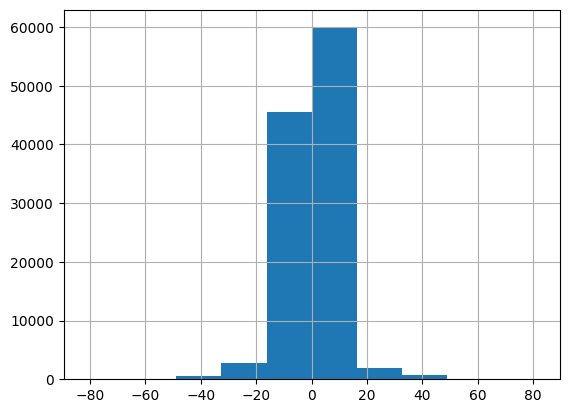

In [63]:
baseline_resids.hist()

### Preprocessing

I create a preprocessor Class, which applies Spline Transformer (cyclical encoding) to the time variables, one-hot encodes the categorical variables, and scales the numeric variables.

In [64]:
hour_spline = SplineTransformer(
    degree=3,
    knots=np.linspace(0,24,7).reshape(-1,1),
    extrapolation='periodic',
    include_bias=False
)

onehot_encoder = OneHotEncoder()
categorical_variables = ['link_id', 'weekday', 'month', 'is_holiday']

scaler = StandardScaler()
numerical_variables = ['current_speed', 'speed_5min_ago', 'speed_10min_ago', 'speed_15min_ago', 'speed_20min_ago', 'speed_25min_ago', 'speed_30min_ago', 'avg_speed_30min', '15min_change']


preprocessor = ColumnTransformer(
    transformers = [
        ('hour_spline', hour_spline,['fractional_hour']),
        ('onehot_encoder', onehot_encoder, categorical_variables),
        ('scaler', scaler, numerical_variables)
        ],
    remainder='passthrough'
    )

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)
X_train_encoded.dtype

dtype('float64')

### Linear Regression with Statsmodels

Requirement 4. Statistical Analysis

Next, I use statsmodels to build my first model: a basic linear regression.

In [38]:
model = sm.OLS(y_train, X_train_encoded).fit()
lr_preds = model.predict(X_test_encoded)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           target_speed   R-squared:                       0.656
Model:                            OLS   Adj. R-squared:                  0.656
Method:                 Least Squares   F-statistic:                 2.666e+04
Date:                Sun, 22 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:08:17   Log-Likelihood:            -1.4660e+06
No. Observations:              447079   AIC:                         2.932e+06
Df Residuals:                  447046   BIC:                         2.932e+06
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            10.4329      0.100    104.155      0.0

/tmp/ipykernel_734/1854741373.py:1: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y_train, X_train_encoded).fit()


The MAE is slightly worse than the baseline model, and the RMSE is a drop better. This means that on average, the errors are a drop higher, but very big errors happen less frequently with this model. For users prioritizing certainty over precision, this might offer a small advantage.

In [39]:
print(f"MAE: {mean_absolute_error(y_test, lr_preds)}")
print(f"RMSE: {root_mean_squared_error(y_test, lr_preds)}")

MAE: 4.786023750001865
RMSE: 7.272564675509734


The min and max errors are significantly lower than the baseline model. The median error is a drop higher than the basline (but still less than one)

In [40]:
lr_resids = y_test - lr_preds
lr_resids.describe()

,target_speed
count,111442.000000
mean,-0.267567
std,7.267674
min,-57.796744
25%,-2.942835
50%,0.334821
75%,3.154614
max,70.111680


<Axes: >

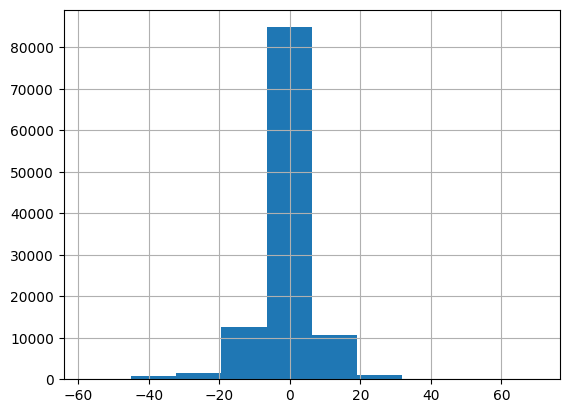

In [41]:
lr_resids.hist()

### SparkMLlib

Requirement 5. Machine Learning with PySpark and MLlib




Next, I use SparkMLLib's GBTRegressor to build a more sophisiticated regression model.

In [42]:
spark = SparkSession.builder.appName("SpeedRegression").getOrCreate()

In [43]:
#preprocessing for Spark
train_df = spark.createDataFrame(
    [(Vectors.dense(row),float(y))
    for row, y in zip(X_train_encoded, y_train)],
    ['features', 'target_30min']
)

test_df = spark.createDataFrame(
    [(Vectors.dense(row), float(y))
    for row, y in zip(X_test_encoded, y_test)],
    ['features', 'target_30min']
)

In [44]:
#building regressor model
regressor = GBTRegressor(
    featuresCol='features',
    labelCol='target_30min',
    maxIter=50,
    maxDepth=4,
    stepSize=0.1,
    seed=42
)

spark_model = regressor.fit(train_df)
spark_preds = spark_model.transform(test_df)

#evaluating model
for metric in ['mae', 'rmse']:
  evaluator = RegressionEvaluator(
      labelCol='target_30min',
      predictionCol='prediction',
      metricName=metric
  )
  print(metric, evaluator.evaluate(spark_preds))

mae 4.49780381310592
rmse 6.932649405807087


The MAE is a tad lower than the baseline, and the RMSE is almost .5 points lower. This model performs on average just a drop better, and offers a real advantage in terms of reliability.


In [45]:
spark_preds = spark_preds.withColumn(
    'residual',
    F.col('target_30min') - F.col('prediction')
)
spark_resids = spark_preds.select('residual').toPandas()['residual']
spark_resids.describe()

,residual
count,111442.000000
mean,-0.397197
std,6.921293
min,-49.673630
25%,-2.892233
50%,0.207384
75%,2.747044
max,79.164669


Looking at the spread of errors, the likelihood of the model predicting too low is reduced with this model, but the max error is still high. So far, this model has achieved the highest RMSE.

<Axes: >

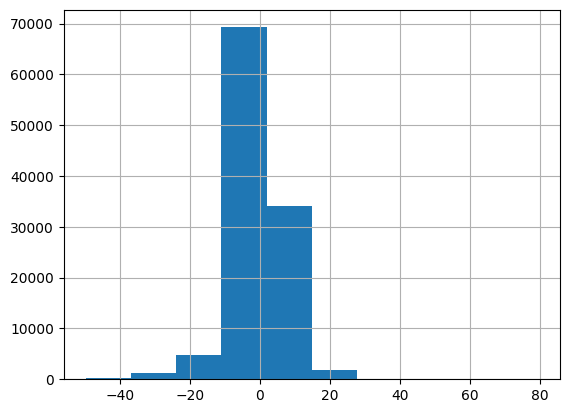

In [46]:
spark_resids.hist()

### Deep Learning Model with TensorFlow

Requirement 6. Deep Learning with TensorFlow and Keras

Lastly, I experiment with a deep learning, neural network model using Keras and TensorFlow.

In [47]:
#preprocessing, and splitting for cross validation
dates = X_train.index.get_level_values('data_as_of')
unique_dates = dates.unique().sort_values()
cutoff = unique_dates[int(len(unique_dates) * 0.8)]

train_mask = dates < cutoff - pd.Timedelta(minutes=30)
val_mask = dates >= cutoff

X_fit, y_fit = X_train.loc[train_mask], y_train.loc[train_mask]
X_val, y_val = X_train.loc[val_mask], y_train.loc[val_mask]

In [48]:
X_train_encoded = preprocessor.fit_transform(X_fit)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)

In [49]:
#building Deep Learning Model architecture
model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train_encoded.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.RootMeanSquaredError(name='rmse')
    ]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_encoded,
    y_fit,
    validation_data=(X_val_encoded, y_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop],
    shuffle=False
)

Epoch 1/100
1397/1397 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 87.4052 - mae: 5.7560 - rmse: 9.3491 - val_loss: 50.6695 - val_mae: 4.5000 - val_rmse: 7.1183
Epoch 2/100
1397/1397 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 40.5206 - mae: 4.1843 - rmse: 6.3656 - val_loss: 47.1658 - val_mae: 4.3508 - val_rmse: 6.8677
Epoch 3/100
1397/1397 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 39.9962 - mae: 4.1637 - rmse: 6.3243 - val_loss: 44.6752 - val_mae: 4.2631 - val_rmse: 6.6840
Epoch 4/100
1397/1397 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 39.5474 - mae: 4.1401 - rmse: 6.2887 - val_loss: 42.8905 - val_mae: 4.2211 - val_rmse: 6.5491
Epoch 5/100
1397/1397 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 39.1421 - mae: 4.1172 - rmse: 6.2564 - val_loss: 41.6929 - val_mae: 4.1950 - val_rmse: 6.4570
Epoch 6/100
1397/1397 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 38.7839 - mae: 4.0956 - rmse: 6.2277 - val_loss: 41.3078 - val_mae: 4.1943 - val_rmse: 6.4271
Epoch 7/100
1397/1397 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - l

In [50]:
#evaluating model
dnn_results = model.evaluate(X_test_encoded, y_test, return_dict=True)
dnn_preds = model.predict(X_test_encoded).ravel()
print(dnn_results)

3483/3483 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 52.1511 - mae: 4.8127 - rmse: 7.2216
3483/3483 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
{'loss': 52.15114974975586, 'mae': 4.812651634216309, 'rmse': 7.2215752601623535}


This model performs no better than the basic linear regression.



In [51]:
dnn_resids = y_test - dnn_preds
dnn_resids.describe()

,target_speed
count,111442.000000
mean,0.257624
std,7.217009
min,-61.690533
25%,-2.514472
50%,0.810177
75%,3.857778
max,79.071311


<Axes: >

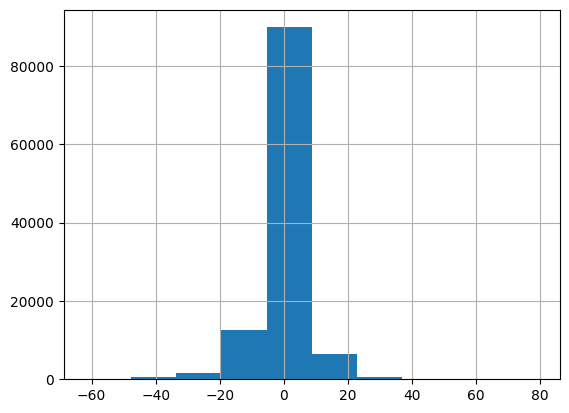

In [52]:
dnn_resids.hist()

Requirement 7. NLP with NLTK and Transformers: N/A , no text data present

### Final Model Evaluation



To gain a better understanding of how my model is performing, I plot the predicted speeds against the actual target speeds. I use plotly make this an  interactive plot, that is easier to explore and interpret.

In [56]:
import numpy as np
import plotly.graph_objects as go

baseline_test_pred = baseline_pred(X_test['current_speed'])

spark_preds_df = spark_preds.select(
    'target_30min', 'prediction'
).toPandas()

fig = go.Figure()

def add_model(actual, predicted, name):
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()

    assert len(actual) == len(predicted)

    fig.add_trace(go.Scattergl(
        x=actual,
        y=predicted,
        mode='markers',
        name=name,
        marker=dict(size=4, opacity=0.25),
        customdata=predicted - actual,
        hovertemplate=(
            'Actual: %{x:.2f}<br>'
            'Predicted: %{y:.2f}<br>'
            'Error (predicted − actual): %{customdata:.2f}'
            '<extra>%{fullData.name}</extra>'
        )
    ))

add_model(y_test, baseline_test_pred, 'Baseline')
add_model(y_test, lr_preds, 'Linear Regression')
add_model(y_test, dnn_preds, 'DNN')

# Keep Spark predictions paired with their own actual values
add_model(
    spark_preds_df['target_30min'],
    spark_preds_df['prediction'],
    'Spark Regressor'
)

low = min(y_test.min(), spark_preds_df['target_30min'].min())
high = max(y_test.max(), spark_preds_df['target_30min'].max())

fig.add_trace(go.Scatter(
    x=[low, high],
    y=[low, high],
    mode='lines',
    name='Perfect prediction',
    line=dict(color='black', dash='dash'),
    hoverinfo='skip'
))

fig.update_layout(
    title='Actual vs. predicted speed — 30 minutes ahead',
    xaxis_title='Actual speed',
    yaxis_title='Predicted speed',
    template='plotly_white',
    height=600
)



def add_average_line(actual, predicted, name):
    data = pd.DataFrame({
        'actual': np.asarray(actual).ravel(),
        'predicted': np.asarray(predicted).ravel()
    }).dropna()

    # Group actual speeds into 5-unit bands
    data['bin'] = np.floor(data['actual'] / 5) * 5

    averages = data.groupby('bin').agg(
        actual=('actual', 'mean'),
        predicted=('predicted', 'mean'),
        count=('predicted', 'size')
    )

    fig.add_trace(go.Scatter(
        x=averages['actual'],
        y=averages['predicted'],
        mode='lines+markers',
        name=f'{name} average',
        customdata=averages['count'],
        hovertemplate=(
            'Mean actual: %{x:.2f}<br>'
            'Mean predicted: %{y:.2f}<br>'
            'Readings: %{customdata}'
            '<extra>%{fullData.name}</extra>'
        )
    ))

add_average_line(y_test, baseline_test_pred, 'Baseline')
add_average_line(y_test, lr_preds, 'Linear Regression')
add_average_line(y_test, dnn_preds, 'DNN')
add_average_line(
    spark_preds_df['target_30min'],
    spark_preds_df['prediction'],
    'Spark Regressor'
)

fig.show()
fig.write_html('model_comparison.html')

A few things are noticeable from this plot: All of the models perform reasonably well, and reasonably similarly, but all have substantial noise and variability.

The superior performance of the Spark Regressor is noticeable in the way its predictions are packed tighter around the actual speeds, but it too has a lot of noise and variation.

Interestingly, the deep leanrning model is the only model predicting negative speeds, which are obviously not possible.

### Conclusion

This project analyzed traffic speeds on the Lincoln Tunnel and GW Bridge, and explored whether it is possible to predict speeds a half hour in advance. The results of this project offer encouraging advice to commuters: While recent changes in speed, time of day and year influence congestion levels, the strongest predictor of speed in the next half hour is still the current speed.
This offers an efficient, reliable and cost-effective solution for commuters.

For a slightly better-performing, and overall more reliable model, with less likelihood of extreme error, the Spark GBTRegressor is a decent solution. It could be implemented as a dashboard, which displays current speed alongside the model's prediction for speed in the half hour. It could also display other statistics, such as how unusual this is for the given road segment. This model could be expanded and trained on more road segments using the same data source.

Some precautions are warranted: While the data is provided by the government of New York, it's reliability hasn't been established. As was noted in the counts of zero-mph records, it's still likely that some of the data is unreliable. Further investigation and validation of the data, might therefore change the results of ourmodeel.